# M12.4.1 — Local analysis of exported multi-task gradients

**Unexecuted, result-only analysis.** Computation lives exclusively in `scripts/m12/run_m12_4_1_gradient_diagnostics.py`. This notebook reads only three CSVs and `run_metadata.json`; no torch, HDF5, checkpoint loading, inference or backward passes. The exported quantities are gradients of the same unweighted standardized per-target MSE at four already-trained eval-mode checkpoints. This differs from the original M12.1/M12.2 weighted training losses and M12.3-S1 exposure.

Hypothesis: mass–spin task gradients on the shared representation are more often opposed than mass–mass gradients, especially in train-defined discordant populations. Compare identical batches. General-population and region-conditioned results remain separate; never pool the stratified schedule into a population conflict rate. A single negative cosine does not demonstrate harmful optimization or architectural inadequacy.

Set an explicit local `DATA_ROOT` and relative `RUN_SUBDIR` below after copying a completed run. A one-model pilot is supported, but four-model comparisons require the all-model export. Checkpoints are verified against recorded configuration/provenance only; local analysis cannot independently authenticate remote weights.

In [1]:
from pathlib import Path
import os, json, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Configure explicitly, or set the established repository environment variable.
DATA_ROOT = "/data/vserrano/cbc_pe_data"  # os.environ.get("CBC_PE_DATA_ROOT")  # or "/your/external/local/data/root"
RUN_SUBDIR = "results/M11_final_G1_500k/M12_4_1/full_seed123_v1"
if not DATA_ROOT:
    raise ValueError("Set DATA_ROOT or CBC_PE_DATA_ROOT to the local external data root")
DATA_ROOT = Path(DATA_ROOT).expanduser().resolve()
RUN_DIR = (DATA_ROOT / RUN_SUBDIR).resolve()
if DATA_ROOT not in RUN_DIR.parents:
    raise ValueError("RUN_SUBDIR must resolve below DATA_ROOT")

def require(ok, message):
    if not ok:
        raise ValueError(message)

meta_path = RUN_DIR / "run_metadata.json"
require(meta_path.is_file(), f"Missing completed-run metadata: {meta_path}")
metadata = json.loads(meta_path.read_text())
require(metadata.get("schema_version") == 1 and metadata.get("status") == "complete", "Unsupported/incomplete schema")
LABELS = ["chirp_mass", "total_mass", "chi_eff"]
TASK_PAIRS = [(0, 1), (0, 2), (1, 2)]
require(metadata["labels"] == LABELS and metadata["dataset_id"] == "M11_final_G1_500k", "Dataset/label contract")
require(metadata["objective"] == "unweighted mean((pred_std[:,k]-target_std[:,k])**2) per task", "Objective changed")
require(metadata["preprocessing"] == dict(enabled=False, already_normalized=True,
    mode="per_sample_per_detector_zscore", eps=1e-6), "Unexpected preprocessing")

In [2]:
EXPECTED_REGIONS = {'version': 'M12.4.1-train-regions-v1', 'reference': 'frozen G1 train only; M12.0 geometry', 'percentile': '100 * searchsorted(sorted_train_distance, distance, side=right) / n_train', 'marginal_distance': 'abs((physical_label - train_mean) / train_std_ddof0)', 'global_distance': 'sqrt(z.T @ frozen_precision @ z)', 'central': 'percentile < 80', 'peripheral': 'percentile >= 80', 'core_annotation': 'marginal percentile <= 50', 'discordant': 'each mass central AND spin peripheral; each mass peripheral AND spin central'}
EXPECTED_LAYERS = {"shallow": ["block1", "block2"], "middle": ["block3", "residual_blocks"],
                   "deep": ["projection", "embedding_layer"]}
require(metadata["region_definitions"] == EXPECTED_REGIONS, "Region definition drift")
require(metadata["layer_groups"] == EXPECTED_LAYERS, "Layer grouping drift")
for filename in ("gradients_per_batch.csv", "gradients_summary.csv", "batch_manifest.csv"):
    path = RUN_DIR / filename
    require(path.is_file(), f"Missing export: {path}")
    require(hashlib.sha256(path.read_bytes()).hexdigest() == metadata["exports"][filename]["sha256"],
            f"Export digest mismatch: {filename}")
results = pd.read_csv(RUN_DIR / "gradients_per_batch.csv")
summary = pd.read_csv(RUN_DIR / "gradients_summary.csv")
samples = pd.read_csv(RUN_DIR / "batch_manifest.csv")
configs = metadata["models"]  # retained plotting order; no training config files read
require(len(configs) == len(set(configs)) and set(configs) <= {"M11", "M12.1", "M12.2", "M12.3-S1"}, "Models")
require(set(results.checkpoint) == set(summary.checkpoint) == set(configs), "Missing model results")
require(all(row["parameters_and_buffers_unchanged"] and row["parameter_grad_fields_unset"]
            for row in metadata["invariants"]), "Frozen-state audit failed")
require({row["checkpoint"] for row in metadata["invariants"]} == set(configs), "Missing state audit")
# Pin expected filenames; recorded hashes identify actual weights without loading them.
TAGS = {"M11": "M11_final_G1_inputzscore_resdilated_emb64_d124_train400k",
        "M12.1": "M12_1a_G1_mahalanobis_alpha0p5_meanone_seed123",
        "M12.2": "M12_2_G1_marginal_alpha0p5_meanone_seed123",
        "M12.3-S1": "M12_3_S1_G1_balanced_sampling_p035_seed123"}
expected_kwargs = dict(n_detectors=3, n_outputs=3, embedding_dim=64, residual_channels=64,
    dilations=[1, 2, 4], residual_kernel_size=7, dropout_conv=.05, dropout_dense=.1, num_groups=8)
for name in configs:
    record = metadata["checkpoints"][name]
    expected = f"M11_final_G1_500k_SimpleCNN_ResidualDilated_{TAGS[name]}_MSELoss_seed123_checkpoint.pt"
    require(Path(record["path"]).name == expected and re.fullmatch("[0-9a-f]{64}", record["sha256"]),
            f"Checkpoint provenance mismatch: {name}")
    mc = record["model_config"]
    require(mc["class_name"] == "SimpleCNN_ResidualDilated" and mc["model_kwargs"] == expected_kwargs
            and mc["label_names"] == LABELS
            and mc["dataset_id"] == metadata["dataset_id"] and mc["input_normalization"] == metadata["preprocessing"]
            and mc["training_seed"] == mc["split_seed"] == 123 and mc["signal_length"] == 16384,
            f"Checkpoint contract mismatch: {name}")
require(metadata["actual_batches"] == (4 if metadata["settings"]["pilot"] else metadata["settings"]["max_batches"]),
        "Global batch budget mismatch")
require(not summary.duplicated(["checkpoint", "pair", "region", "group"]).any(), "Duplicate summary row")
expected_summary_keys = set(results[["checkpoint", "pair", "region", "group"]].itertuples(index=False, name=None))
require(expected_summary_keys == set(summary[["checkpoint", "pair", "region", "group"]].itertuples(index=False, name=None)),
        "Missing summary groups")
require(not results.duplicated(["checkpoint", "batch_id", "pair", "group"]).any(), "Duplicate gradient row")
require(not samples.duplicated(["batch_id", "sample_order"]).any(), "Duplicate sample order")
manifest = {b["batch_id"]: b for b in metadata["batch_manifest"]}
require(set(manifest) == set(range(metadata["actual_batches"])) == set(samples.batch_id), "Batch coverage")
require(set(results.batch_id) == set(manifest), "Gradient batch coverage")
pair_names = {LABELS[a]+" / "+LABELS[b] for a, b in TASK_PAIRS}
for bid, batch in manifest.items():
    sub = samples[samples.batch_id.eq(bid)].sort_values("sample_order")
    require(sub.sample_order.tolist() == list(range(metadata["settings"]["batch_size"])), "Sample order")
    require(sub.row_id.tolist() == batch["row_ids"] and sub.row_id.nunique() == len(sub), "Row identity")
    require(set(sub.region) == {batch["region"]} and set(sub.ids_sha256) == {batch["ids_sha256"]}, "Sample annotations")
    # array_hash uses dtype+shape as well as bytes, matching the exported train ID contract.
    ids = sub.row_id.to_numpy(dtype=np.dtype(metadata["train_ids_dtype"]))
    digest = hashlib.sha256(str((ids.dtype.str, ids.shape)).encode()+ids.tobytes()).hexdigest()
    require(digest == batch["ids_sha256"], "Batch row digest")
    block = results[results.batch_id.eq(bid)]
    require(set(block.region) == {batch["region"]} and set(block.ids_sha256) == {digest}, "Unpaired gradients")
    for name in configs:
        frame = block[block.checkpoint.eq(name)]
        require(set(zip(frame.pair, frame.group)) == {(p, g) for p in pair_names
            for g in ["all_shared", *EXPECTED_LAYERS]} and len(frame) == 12, "Incomplete pair/layer coverage")
# Check region membership from exported train percentiles, not local labels or a refitted CDF.
for row in samples.to_dict("records"):
    q = [row[label+"_percentile"] for label in LABELS]
    require(all(np.isfinite(q)) and all(0 <= x <= 100 for x in q)
            and 0 <= row["global_percentile"] <= 100, "Invalid percentile")
    memberships = {"general", "global_central" if row["global_percentile"] < 80 else "global_peripheral"}
    for j, label in enumerate(LABELS):
        memberships.add(label + ("_central" if q[j] < 80 else "_peripheral"))
    for j, label in enumerate(LABELS[:2]):
        if q[j] < 80 and q[2] >= 80:
            memberships.add(label+"_central_spin_peripheral")
        if q[j] >= 80 and q[2] < 80:
            memberships.add(label+"_peripheral_spin_central")
    require(set(json.loads(row["memberships"])) == memberships and row["region"] in memberships, "Region mismatch")
finite = np.isfinite(results.cosine)
require((np.abs(results.loc[finite, "cosine"]) <= 1+1e-10).all(), "Cosine outside bounds")
require(np.array_equal(results.loc[finite, "negative_cosine"].to_numpy(),
                       (results.loc[finite, "cosine"] < 0).astype(float).to_numpy()), "Negative indicator mismatch")
require(results.loc[~finite, "negative_cosine"].isna().all(), "Undefined cosine counted as nonnegative")
selected_regions = [manifest[i]["region"] for i in sorted(manifest)]
display(pd.DataFrame(metadata["checkpoints"]).T[["path", "sha256", "epoch"]],
        pd.DataFrame(metadata["population"]), pd.DataFrame(metadata["invariants"]))
print(metadata["environment"])

,path,sha256,epoch
M11,/data/vserrano/cbc_pe_data/models/checkpoints/...,3670f0dbe985cf4b3405ee47b970eedd56f573d0cd5741...,75
M12.1,/data/vserrano/cbc_pe_data/models/checkpoints/...,2b573cc67b3bcee54881f174381706286db6a41ef20c52...,51
M12.2,/data/vserrano/cbc_pe_data/models/checkpoints/...,8d33c89ebc670a0570aac7f88da012ac6975900f2ebcac...,83
M12.3-S1,/data/vserrano/cbc_pe_data/models/checkpoints/...,45826a25ac854a8b85e2b65b186e810468e6646fe4b671...,29


,region,population,batches,sampled_rows
0,general,400000,3,96
1,global_central,319999,3,96
2,global_peripheral,80001,2,64
3,chirp_mass_central,319999,2,64
4,chirp_mass_peripheral,80001,2,64
5,total_mass_central,319999,2,64
6,total_mass_peripheral,80001,2,64
7,chi_eff_central,319999,2,64
8,chi_eff_peripheral,80001,2,64
9,chirp_mass_central_spin_peripheral,64739,2,64


,checkpoint,parameters_and_buffers_unchanged,parameter_grad_fields_unset,cuda_peak_MiB
0,M11,True,True,567.322754
1,M12.1,True,True,567.323242
2,M12.2,True,True,567.323242
3,M12.3-S1,True,True,567.323242


{'python': '3.9.23 (main, Jun  5 2025, 13:40:20) \n[GCC 11.2.0]', 'torch': '1.9.1+cu111', 'numpy': '1.23.5', 'h5py': '3.14.0', 'pandas': '1.5.3', 'platform': 'Linux-4.8.6-300.fc25.x86_64-x86_64-with-glibc2.24', 'cpu': 'x86_64', 'cpu_count': 7, 'threads': 2, 'device': 'cuda', 'cuda': '11.1', 'cudnn': 8005, 'gpu': 'Tesla P100-SXM2-16GB'}


## Frozen train metadata and regions
On the VM, the CLI scans only train labels (400,000 × 3, about 9.6 MB in float64) and split metadata, then reads bounded strain batches. This local notebook reads none of those inputs. The M12.0 split/scaler hashes and train geometry are required. Use its population standard deviation and right-side empirical CDF. Central means percentile <80, peripheral ≥80; central core ≤50 is a separate descriptive annotation. Mass regions are defined separately for chirp_mass and total_mass. Global regions use train Mahalanobis percentiles. These absolute-distance regions combine both signed tails.

All four checkpoints must share preprocessing: stored `(3,16384)` inputs, already z-scored per detector, no extra normalization. Label scaling reproduces the loader's float32 `(y−mean)/(std+1e−8)` exactly; the float64 region geometry is distinct from that saved training scaler.

These definitions were applied by the CLI; this notebook verifies exported annotations only. Shallow = block1/block2; middle = block3/residual_blocks; deep = projection/embedding. All backbone biases are included. The three task-specific rows of the linear output head are excluded; None-gradient coverage is recorded in metadata.

In [3]:
overlap = pd.DataFrame([[len(set(a["row_ids"]) & set(b["row_ids"])) for b in manifest.values()]
                        for a in manifest.values()])
require(overlap.to_numpy().tolist() == metadata["overlap"], "Overlap provenance mismatch")
display(overlap, pd.DataFrame(metadata["coverage"]))
print("Total sample draws / unique train rows:", len(samples), samples.row_id.nunique())
# General and conditioned summaries are intentionally separate.
display(summary[summary.region.eq("general")])
display(summary[~summary.region.eq("general")])

,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,32,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,32,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,32,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,32,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,32,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,32,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,32,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,32,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,32,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,32,...,0,0,0,0,0,0,0,0,0,0


,checkpoint,batch_id,region,group,task,tensors,elements,none_parameters,none_tensors,nonzero_elements
0,M11,0,general,shallow,chirp_mass,8,9104,[],0,9104
1,M11,0,general,shallow,total_mass,8,9104,[],0,9104
2,M11,0,general,shallow,chi_eff,8,9104,[],0,9104
3,M11,0,general,middle,chirp_mass,28,206144,[],0,206144
4,M11,0,general,middle,total_mass,28,206144,[],0,206144
...,...,...,...,...,...,...,...,...,...,...
1339,M12.3-S1,27,global_central,deep,total_mass,8,20992,[],0,20992
1340,M12.3-S1,27,global_central,deep,chi_eff,8,20992,[],0,20992
1341,M12.3-S1,27,global_central,all_shared,chirp_mass,44,236240,[],0,236240
1342,M12.3-S1,27,global_central,all_shared,total_mass,44,236240,[],0,236240


Total sample draws / unique train rows: 896 896


,checkpoint,pair,group,region,batches,undefined_cosines,negative_fraction,uncertainty,cosine_n,cosine_q25,...,norm_ratio_a_over_b_median,norm_ratio_a_over_b_q75,norm_ratio_b_over_a_n,norm_ratio_b_over_a_q25,norm_ratio_b_over_a_median,norm_ratio_b_over_a_q75,cosine_median_ci_low,cosine_median_ci_high,negative_fraction_ci_low,negative_fraction_ci_high
0,M11,chirp_mass / total_mass,shallow,general,3,0,0.000000,insufficient batches,3,0.371659,...,1.016542,1.129435,3,0.894334,0.983727,0.990594,NaN,NaN,NaN,NaN
1,M11,chirp_mass / chi_eff,shallow,general,3,0,0.000000,insufficient batches,3,0.128582,...,0.354858,0.620620,3,1.973105,2.818027,2.832137,NaN,NaN,NaN,NaN
2,M11,total_mass / chi_eff,shallow,general,3,0,0.333333,insufficient batches,3,0.012556,...,0.353957,0.533721,3,2.113387,2.825202,2.859266,NaN,NaN,NaN,NaN
3,M11,chirp_mass / total_mass,middle,general,3,0,0.333333,insufficient batches,3,0.271088,...,1.065944,1.073548,3,0.931537,0.938136,0.997265,NaN,NaN,NaN,NaN
4,M11,chirp_mass / chi_eff,middle,general,3,0,0.333333,insufficient batches,3,-0.008743,...,0.379128,0.449413,3,2.280914,2.637635,3.048757,NaN,NaN,NaN,NaN
5,M11,total_mass / chi_eff,middle,general,3,0,0.333333,insufficient batches,3,-0.100632,...,0.350670,0.419109,3,2.451384,2.851686,3.063431,NaN,NaN,NaN,NaN
6,M11,chirp_mass / total_mass,deep,general,3,0,0.000000,insufficient batches,3,0.520011,...,0.889395,1.203713,3,0.891554,1.124360,1.266944,NaN,NaN,NaN,NaN
7,M11,chirp_mass / chi_eff,deep,general,3,0,1.000000,insufficient batches,3,-0.073048,...,0.410031,0.485745,3,2.109957,2.438837,2.468471,NaN,NaN,NaN,NaN
8,M11,total_mass / chi_eff,deep,general,3,0,0.666667,insufficient batches,3,-0.146795,...,0.461023,0.512631,3,1.970695,2.169089,2.436410,NaN,NaN,NaN,NaN
9,M11,chirp_mass / total_mass,all_shared,general,3,0,0.000000,insufficient batches,3,0.355949,...,1.008464,1.110176,3,0.908383,0.991607,1.053432,NaN,NaN,NaN,NaN


,checkpoint,pair,group,region,batches,undefined_cosines,negative_fraction,uncertainty,cosine_n,cosine_q25,...,norm_ratio_a_over_b_median,norm_ratio_a_over_b_q75,norm_ratio_b_over_a_n,norm_ratio_b_over_a_q25,norm_ratio_b_over_a_median,norm_ratio_b_over_a_q75,cosine_median_ci_low,cosine_median_ci_high,negative_fraction_ci_low,negative_fraction_ci_high
12,M11,chirp_mass / total_mass,shallow,global_central,3,0,0.000000,insufficient batches,3,0.823656,...,1.442084,1.609045,3,0.628251,0.693441,0.696706,NaN,NaN,NaN,NaN
13,M11,chirp_mass / chi_eff,shallow,global_central,3,0,0.333333,insufficient batches,3,0.156539,...,0.529259,0.783196,3,1.426814,1.889433,1.922350,NaN,NaN,NaN,NaN
14,M11,total_mass / chi_eff,shallow,global_central,3,0,0.333333,insufficient batches,3,0.185607,...,0.367010,0.546486,3,2.051101,2.724720,3.098643,NaN,NaN,NaN,NaN
15,M11,chirp_mass / total_mass,middle,global_central,3,0,0.000000,insufficient batches,3,0.823811,...,1.593520,1.659650,3,0.603495,0.627542,0.641328,NaN,NaN,NaN,NaN
16,M11,chirp_mass / chi_eff,middle,global_central,3,0,0.333333,insufficient batches,3,0.045500,...,0.917834,1.064485,3,0.957596,1.089522,1.264620,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
619,M12.3-S1,chirp_mass / chi_eff,deep,total_mass_peripheral_spin_central,2,0,0.500000,insufficient batches,2,-0.063107,...,0.590416,0.674114,2,1.580681,1.841774,2.102867,NaN,NaN,NaN,NaN
620,M12.3-S1,total_mass / chi_eff,deep,total_mass_peripheral_spin_central,2,0,0.000000,insufficient batches,2,0.078301,...,0.600636,0.668024,2,1.556478,1.753173,1.949868,NaN,NaN,NaN,NaN
621,M12.3-S1,chirp_mass / total_mass,all_shared,total_mass_peripheral_spin_central,2,0,0.000000,insufficient batches,2,0.634355,...,1.317769,1.580993,2,0.722604,0.902973,1.083341,NaN,NaN,NaN,NaN
622,M12.3-S1,chirp_mass / chi_eff,all_shared,total_mass_peripheral_spin_central,2,0,0.000000,insufficient batches,2,0.062604,...,0.474575,0.551223,2,1.972650,2.352615,2.732579,NaN,NaN,NaN,NaN


## Distribution summaries and descriptive batch uncertainty
Fractions use only finite cosines; undefined counts are shown. Report norms and dot products alongside cosines because orientation alone ignores magnitude. Intervals below resample diagnostic batches within each region, never examples within a batch. They describe sensitivity to the sampled batches conditional on these checkpoints, batch size and regions, not training-seed variability. Within-region draws are disjoint but sampled without replacement; across-region rows overlap. Regions and layers are dependent, so intervals are exploratory, not independent tests or multiplicity-adjusted evidence. Intervals are withheld with fewer than five finite batches; default full runs have only two or three per region. Do not inflate the resource budget merely to obtain an interval. Paired differences retain the same batch identity across checkpoints.

In [4]:
BOOTSTRAP_REPLICATES = 400
MIN_CI_BATCHES = 5
rng_boot = np.random.default_rng(metadata["settings"]["seed"] + 1)
def describe(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return dict(n=0, q25=np.nan, median=np.nan, q75=np.nan)
    q = np.quantile(values, [.25, .5, .75])
    return dict(n=len(values), q25=q[0], median=q[1], q75=q[2])

def interval(values, statistic):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < MIN_CI_BATCHES:
        return np.nan, np.nan
    draws = rng_boot.choice(values, size=(BOOTSTRAP_REPLICATES, len(values)), replace=True)
    stats = np.median(draws, axis=1) if statistic == "median" else np.mean(draws < 0, axis=1)
    return tuple(np.quantile(stats, [.025, .975]))


from itertools import combinations
paired_rows = []
for reference, candidate in combinations(configs, 2):
    left = results[results.checkpoint.eq(candidate)]
    right = results[results.checkpoint.eq(reference)]
    paired = left.merge(right, on=["batch_id", "region", "pair", "group", "ids_sha256"],
                        suffixes=("_candidate", "_reference"), validate="one_to_one")
    require(len(paired) == len(left) == len(right), "Incomplete paired comparison")
    for key, frame in paired.groupby(["region", "pair", "group"], sort=False):
        delta = frame.cosine_candidate - frame.cosine_reference
        lo, hi = interval(delta, "median")
        paired_rows.append(dict(candidate=candidate, reference=reference, region=key[0], pair=key[1], group=key[2],
                                **describe(delta), median_delta_ci_low=lo, median_delta_ci_high=hi))
paired_summary = pd.DataFrame(paired_rows)
if paired_summary.empty:
    print("Single-model pilot: paired checkpoint contrasts unavailable")
else:
    display(paired_summary[paired_summary.region.eq("general")])
    display(paired_summary[~paired_summary.region.eq("general")])


,candidate,reference,region,pair,group,n,q25,median,q75,median_delta_ci_low,median_delta_ci_high
0,M12.1,M11,general,chirp_mass / total_mass,shallow,3,0.045074,0.096580,0.354590,NaN,NaN
1,M12.1,M11,general,chirp_mass / chi_eff,shallow,3,0.011875,0.078642,0.133488,NaN,NaN
2,M12.1,M11,general,total_mass / chi_eff,shallow,3,-0.014326,0.016054,0.110169,NaN,NaN
3,M12.1,M11,general,chirp_mass / total_mass,middle,3,-0.035802,0.060504,0.390177,NaN,NaN
4,M12.1,M11,general,chirp_mass / chi_eff,middle,3,0.010649,0.110030,0.199711,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
787,M12.3-S1,M12.2,general,chirp_mass / chi_eff,deep,3,-0.198384,-0.128856,-0.061392,NaN,NaN
788,M12.3-S1,M12.2,general,total_mass / chi_eff,deep,3,-0.064741,0.005118,0.218979,NaN,NaN
789,M12.3-S1,M12.2,general,chirp_mass / total_mass,all_shared,3,-0.425165,-0.089868,-0.071032,NaN,NaN
790,M12.3-S1,M12.2,general,chirp_mass / chi_eff,all_shared,3,0.056838,0.071784,0.085336,NaN,NaN


,candidate,reference,region,pair,group,n,q25,median,q75,median_delta_ci_low,median_delta_ci_high
12,M12.1,M11,global_central,chirp_mass / total_mass,shallow,3,-0.219935,-0.192196,-0.139740,NaN,NaN
13,M12.1,M11,global_central,chirp_mass / chi_eff,shallow,3,0.023806,0.077297,0.152340,NaN,NaN
14,M12.1,M11,global_central,total_mass / chi_eff,shallow,3,-0.010138,0.156373,0.203455,NaN,NaN
15,M12.1,M11,global_central,chirp_mass / total_mass,middle,3,-0.169676,-0.085539,-0.060252,NaN,NaN
16,M12.1,M11,global_central,chirp_mass / chi_eff,middle,3,-0.038491,0.133871,0.198418,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
931,M12.3-S1,M12.2,total_mass_peripheral_spin_central,chirp_mass / chi_eff,deep,2,-0.203758,-0.183432,-0.163106,NaN,NaN
932,M12.3-S1,M12.2,total_mass_peripheral_spin_central,total_mass / chi_eff,deep,2,-0.109207,-0.103942,-0.098677,NaN,NaN
933,M12.3-S1,M12.2,total_mass_peripheral_spin_central,chirp_mass / total_mass,all_shared,2,0.012219,0.074364,0.136509,NaN,NaN
934,M12.3-S1,M12.2,total_mass_peripheral_spin_central,chirp_mass / chi_eff,all_shared,2,-0.164253,-0.074492,0.015269,NaN,NaN


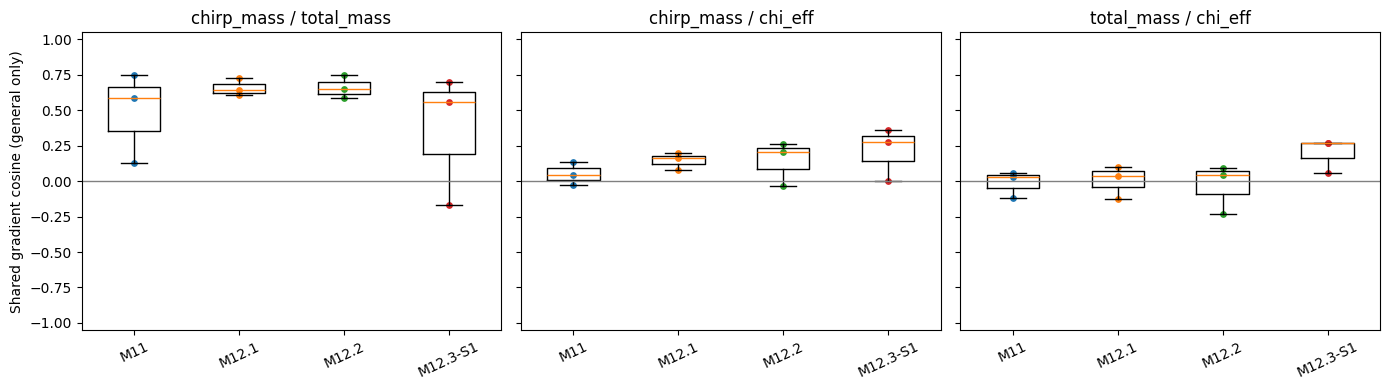

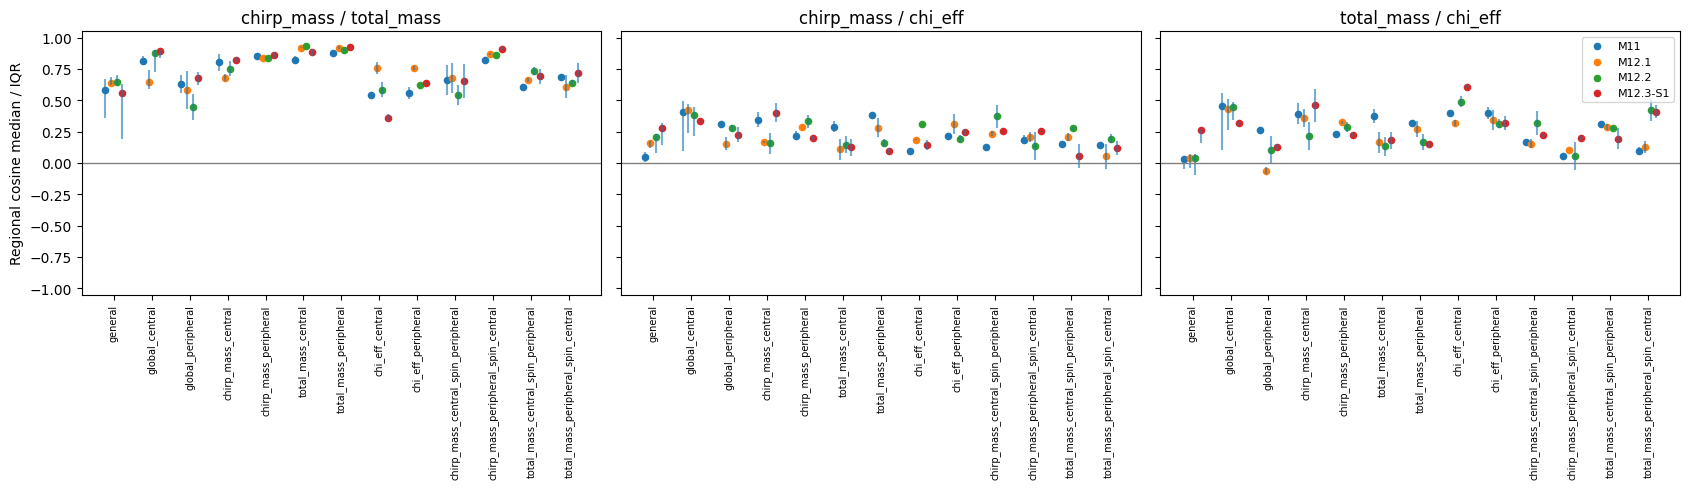

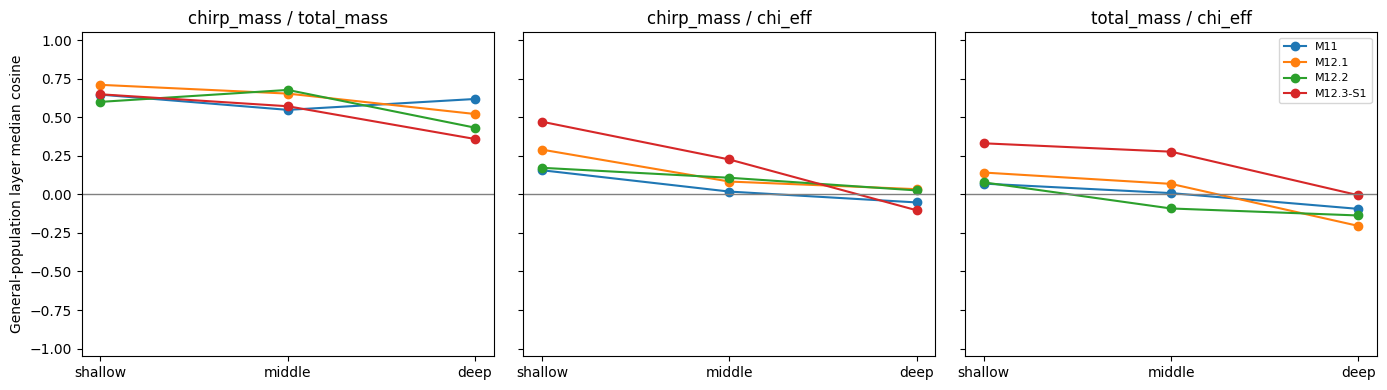

In [5]:
# Three bounded figures; each mark is a measured batch or a within-region summary.
pairs = [LABELS[a]+" / "+LABELS[b] for a, b in TASK_PAIRS]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, pair in zip(axes, pairs):
    for i, name in enumerate(configs):
        vals = results.loc[results.checkpoint.eq(name) & results.pair.eq(pair)
                           & results.group.eq("all_shared") & results.region.eq("general"), "cosine"].dropna()
        if len(vals):
            ax.boxplot([vals.to_numpy()], positions=[i], widths=.5)
            ax.scatter(np.full(len(vals), i), vals, s=15)
    ax.axhline(0, color="gray", lw=1)
    ax.set_xticks(range(len(configs))); ax.set_xticklabels(list(configs), rotation=25)
    ax.set_title(pair); ax.set_ylim(-1.05, 1.05)
axes[0].set_ylabel("Shared gradient cosine (general only)")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
active_regions = list(dict.fromkeys(selected_regions))
for ax, pair in zip(axes, pairs):
    for i, name in enumerate(configs):
        frame = summary[summary.checkpoint.eq(name) & summary.pair.eq(pair) & summary.group.eq("all_shared")].set_index("region").reindex(active_regions)
        x = np.arange(len(active_regions)) + (i-1.5)*.15
        ax.vlines(x, frame.cosine_q25, frame.cosine_q75, alpha=.6)
        ax.scatter(x, frame.cosine_median, label=name, s=20)
    ax.axhline(0, color="gray", lw=1)
    ax.set_xticks(range(len(active_regions))); ax.set_xticklabels(active_regions, rotation=90, fontsize=7)
    ax.set_title(pair); ax.set_ylim(-1.05, 1.05)
axes[0].set_ylabel("Regional cosine median / IQR")
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, pair in zip(axes, pairs):
    for name in configs:
        frame = summary[summary.checkpoint.eq(name) & summary.pair.eq(pair) & summary.region.eq("general")].set_index("group").reindex(["shallow", "middle", "deep"])
        ax.plot(range(3), frame.cosine_median, marker="o", label=name)
    ax.axhline(0, color="gray", lw=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(["shallow", "middle", "deep"])
    ax.set_title(pair); ax.set_ylim(-1.05, 1.05)
axes[0].set_ylabel("General-population layer median cosine")
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()

,checkpoint,pair,region,group,batches,undefined_cosines,negative_fraction,norm_a_median,norm_b_median,norm_ratio_a_over_b_median,cosine_median
0,M11,chirp_mass / total_mass,general,shallow,3,0,0.000000,0.381516,0.375307,1.016542,0.646255
1,M11,chirp_mass / chi_eff,general,shallow,3,0,0.000000,0.381516,0.580567,0.354858,0.155994
2,M11,total_mass / chi_eff,general,shallow,3,0,0.333333,0.375307,0.580567,0.353957,0.069393
3,M11,chirp_mass / total_mass,general,middle,3,0,0.333333,0.499181,0.527332,1.065944,0.547390
4,M11,chirp_mass / chi_eff,general,middle,3,0,0.333333,0.499181,1.249274,0.379128,0.017655
5,M11,total_mass / chi_eff,general,middle,3,0,0.333333,0.527332,1.249274,0.350670,0.007782
6,M11,chirp_mass / total_mass,general,deep,3,0,0.000000,0.311381,0.363632,0.889395,0.617989
7,M11,chirp_mass / chi_eff,general,deep,3,0,1.000000,0.311381,0.777863,0.410031,-0.052732
8,M11,total_mass / chi_eff,general,deep,3,0,0.666667,0.363632,0.777863,0.461023,-0.094506
9,M11,chirp_mass / total_mass,general,all_shared,3,0,0.000000,0.701209,0.782028,1.008464,0.585529


,checkpoint,pair,region,group,batches,undefined_cosines,negative_fraction,norm_a_median,norm_b_median,norm_ratio_a_over_b_median,cosine_median
12,M11,chirp_mass / total_mass,global_central,shallow,3,0,0.000000,0.663878,0.464695,1.442084,0.844075
13,M11,chirp_mass / chi_eff,global_central,shallow,3,0,0.333333,0.663878,0.640109,0.529259,0.485267
14,M11,total_mass / chi_eff,global_central,shallow,3,0,0.333333,0.464695,0.640109,0.367010,0.540195
15,M11,chirp_mass / total_mass,global_central,middle,3,0,0.000000,0.794754,0.520654,1.593520,0.846261
16,M11,chirp_mass / chi_eff,global_central,middle,3,0,0.333333,0.794754,0.959125,0.917834,0.285870
...,...,...,...,...,...,...,...,...,...,...,...
619,M12.3-S1,chirp_mass / chi_eff,total_mass_peripheral_spin_central,deep,2,0,0.500000,0.685526,1.254959,0.590416,-0.022057
620,M12.3-S1,total_mass / chi_eff,total_mass_peripheral_spin_central,deep,2,0,0.000000,0.709152,1.254959,0.600636,0.102554
621,M12.3-S1,chirp_mass / total_mass,total_mass_peripheral_spin_central,all_shared,2,0,0.000000,2.258214,1.600963,1.317769,0.716025
622,M12.3-S1,chirp_mass / chi_eff,total_mass_peripheral_spin_central,all_shared,2,0,0.000000,2.258214,4.389716,0.474575,0.118697


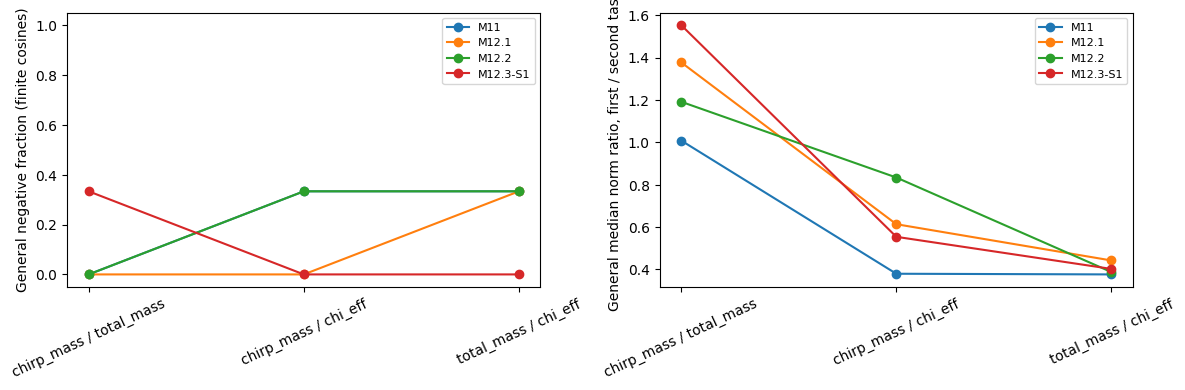

In [6]:
# Task gradient magnitudes and negative frequencies, kept separate by region.
cols = ["checkpoint", "pair", "region", "group", "batches", "undefined_cosines", "negative_fraction",
        "norm_a_median", "norm_b_median", "norm_ratio_a_over_b_median", "cosine_median"]
display(summary.loc[summary.region.eq("general"), cols])
display(summary.loc[~summary.region.eq("general"), cols])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in configs:
    frame = summary[summary.checkpoint.eq(name) & summary.region.eq("general") & summary.group.eq("all_shared")].set_index("pair")
    frame = frame.reindex([LABELS[a]+" / "+LABELS[b] for a,b in TASK_PAIRS])
    axes[0].plot(range(3), frame.negative_fraction, marker="o", label=name)
    axes[1].plot(range(3), frame.norm_ratio_a_over_b_median, marker="o", label=name)
for ax in axes:
    ax.set_xticks(range(3)); ax.set_xticklabels(frame.index, rotation=25)
    ax.legend(fontsize=8)
axes[0].set_ylabel("General negative fraction (finite cosines)"); axes[0].set_ylim(-.05, 1.05)
axes[1].set_ylabel("General median norm ratio, first / second task")
fig.tight_layout()
plt.show()

## Interpretation and decision record

- **Audit:** [run path, input hashes, versions/device, state invariants, unused/zero-gradient coverage, timings and peak GPU memory]. Checkpoint hashes document the actual files; they do not independently prove historical authenticity. No full strain digest is taken.
- **General population:** [mass–mass versus both mass–spin pairs, median/IQR cosine, negative fractions, norm ratios and undefined counts]. Do not substitute a pooled stratified result.
- **Regions and depth:** [separate chirp_mass and total_mass central/peripheral/discordant contrasts; shallow/middle/deep agreement; overlapping rows and sparse batch counts]. Absolute-distance regions combine signed tails. Minibatch means can conceal individual-example conflict; changing batch size changes the estimand.
- **Paired checkpoint contrasts:** [differences on identical batch IDs, with uncertainty only where supported]. A four-batch M11 pilot cannot answer the four-model scientific question.
- **Decision:** Repeated, nondegenerate mass–spin opposition may motivate a separately authorized controlled intervention; absent or mixed evidence does not justify an architectural claim. These eval-mode gradients describe trained endpoints, not interference throughout optimization. No cross-seed reproducibility claim is possible. Future model selection remains validation-only with the provisional ≤2% per-label RMSE guardrail plus slopes, tails, low-SNR and chi_eff assessment. No follow-on training is launched here.

Full default budget: 28 batches total per model across 13 regions, usually 2–3 batches per region; CIs are withheld below five batches. Bootstrap describes conditional batch sampling, not training seeds; disjoint within-region draws are without replacement and across-region draws overlap. Treat plots as exploratory, without independent/multiple-testing claims.

## Terminal execution and transfer

From the repository on the VM, with the existing environment and `CBC_PE_DATA_ROOT` set:

```bash
python scripts/m12/run_m12_4_1_gradient_diagnostics.py --models M11 --device cpu --pilot --max-batches 4 --batch-size 32 --seed 123 --output-dir "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_4_1/pilot_cpu_seed123_v1"
python scripts/m12/run_m12_4_1_gradient_diagnostics.py --models M11 M12.1 M12.2 M12.3-S1 --device cuda --max-batches 28 --batch-size 32 --seed 123 --output-dir "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_4_1/full_seed123_v1"
```

Optional GPU pilot: replace `--device cpu` with `--device cuda` and use a new `pilot_cuda_seed123_v1` output tag. `--data-root /existing/external/root` overrides the environment. An existing output directory is refused. Omitting `--output-dir` creates a timestamped directory under `results/M11_final_G1_500k/M12_4_1/`. The diagnostic seed controls sampling only; the frozen training/split seed stays 123.

Copy only the four small exports to the same relative directory under the local data root, using user-operated `scp` or `rsync` without `--delete`. Example from the local machine (substitute the remote host and actual remote data path):

```bash
mkdir -p "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_4_1/full_seed123_v1"
rsync -av --ignore-existing --include='*.csv' --include='run_metadata.json' --exclude='*' USER@VM:/REMOTE_DATA_ROOT/results/M11_final_G1_500k/M12_4_1/full_seed123_v1/ "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_4_1/full_seed123_v1/"
```

`gradients_per_batch.csv`: model (`checkpoint`), pair, region, group, batch ID/hash, per-task losses, norms, both ratios, dot, cosine and nullable negative indicator. `gradients_summary.csv`: model/pair/region/group distribution summaries, finite counts, negative fractions and eligible descriptive CIs (no batch ID because aggregated). `batch_manifest.csv`: one row per ordered sample per batch, original train row ID, region, percentiles, memberships and batch digest; common to every model. `run_metadata.json`: schema/completion status, all contracts, exact paths/hashes, architecture/layer inventory, versions/device/settings, state and coverage audits, timings, population/overlap counts and export digests. No strain or parameter-gradient vectors are exported.

Lightweight checks: `PYTHONDONTWRITEBYTECODE=1 python -m unittest discover -s tests -p 'test_m12_4_1_gradient_diagnostics.py'`. These use synthetic fixtures, never research checkpoints. Actual P100/PyTorch 1.9.1 execution requires the manual pilot; unsupported deterministic kernels should fail rather than silently switch algorithms.

### Discovered checkpoint filenames

- M11: `M11_final_G1_500k_SimpleCNN_ResidualDilated_M11_final_G1_inputzscore_resdilated_emb64_d124_train400k_MSELoss_seed123_checkpoint.pt`
- M12.1: `M11_final_G1_500k_SimpleCNN_ResidualDilated_M12_1a_G1_mahalanobis_alpha0p5_meanone_seed123_MSELoss_seed123_checkpoint.pt`
- M12.2: `M11_final_G1_500k_SimpleCNN_ResidualDilated_M12_2_G1_marginal_alpha0p5_meanone_seed123_MSELoss_seed123_checkpoint.pt`
- M12.3-S1: `M11_final_G1_500k_SimpleCNN_ResidualDilated_M12_3_S1_G1_balanced_sampling_p035_seed123_MSELoss_seed123_checkpoint.pt`

Processed inputs:

- `m11_final_G1_500k_trainio.h5`
- `M11_final_G1_500k_splits_train400000_val40000_cal30000_test30000_seed123.npz`
- `M11_final_G1_500k_label_stats_train_only_train400000_val40000_cal30000_test30000_seed123.npz`

# Large-sample extension — schema v2 (independent analysis section)

The preceding initial-study cells and saved outputs are preserved. Their source exports remain untouched. **Run this section independently** to analyze a new v2 run; do not reinterpret the saved 28-batch results as a large study. This section reads only exported CSV/JSON scalars and manifests. No checkpoints, HDF5 or GPU libraries are loaded.

The initial complete run has only 2–3 batches per region and all 624 summary rows mark uncertainty unavailable. The new predefined study uses 40,000 distinct general-population train examples, batch size64, and all four fixed checkpoints. Expected budget: 625 batches/model, 2,500 forward calls and 7,500 per-task backward calls. Cumulative actual counts are 2,560, 5,056, 10,048, 20,032 and 40,000 (thresholds rounded up to batch boundaries; no reruns). No optional stopping or automatic budget expansion.

**Regional budget:** optional `--regions` cohorts each receive `--region-examples` (default5,000), charged to the same global `--examples` budget. General receives the remainder. Independent without-replacement regional samples may overlap general/other regions; the distinct union is at most the declared budget and is not automatically refilled. No pooled population estimate or cross-region independent confidence test is constructed. More than40,000 requires explicit `--examples`, capped at400,000. A census is exact only for a cohort that includes every eligible row, conditional on the fixed checkpoint and numerical evaluation.

**Two estimands:** minibatch geometry describes fixed-size random train minibatches. Sample-aggregate geometry uses `sum(n_batch*g_batch)/sum(n_batch)`, never a mean cosine. All examples, including a partial final batch, enter aggregate gradients; partial batches remain in scalar exports but are excluded from primary full-size minibatch inference. Combined ordinary-MSE gradient is `(g_chirp+g_totalmass+g_spin)/3`: positive dot means a negative first-order change along ordinary SGD's negative combined-gradient direction, with sufficiently small step. This is not the exact Adam update, which depends on optimizer history/preconditioning/weight decay.

**Predefined uncertainty and stability:** 400 paired batch bootstrap replicates on the same finite full-size batches across models; aggregate weighted delete-group normal intervals (20 groups by default) with finite-population correction. Equal-size groups recover the usual delete-group jackknife; unequal block sizes use documented weighted pseudo-values and only approximate coverage. No training-seed variation is estimated. Tiny aggregate norms use `max(1e-12, 1e-6*batch-gradient-RMS)` and yield undefined cosine. Aggregate normal intervals can exceed a metric's natural support; they are not silently clipped. Sparse data, undefined leave-group geometry and wide intervals are indeterminate.

Adequacy requires ≥30 batches and ≥95% common finite minibatch values (or finite eligible aggregate intervals). Descriptive stability requires two successive absolute changes≤.03 and current95% CI halfwidth≤.10 for cosine/negative fraction. These thresholds are recorded before evaluation, not universal scientific acceptance criteria. Nested looks are dependent; intervals are unadjusted marginal intervals, not simultaneous guarantees or a stopping rule.

In [7]:
from pathlib import Path
import os, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

LARGE_DATA_ROOT = DATA_ROOT  # set explicitly if needed
LARGE_RUN_SUBDIR = "results/M11_final_G1_500k/M12_4_1/regional_5k_seed123_v1"
if not LARGE_DATA_ROOT:
    raise ValueError("Set LARGE_DATA_ROOT or CBC_PE_DATA_ROOT to the local external data root")
large_root = Path(LARGE_DATA_ROOT).expanduser().resolve()
large_dir = (large_root / LARGE_RUN_SUBDIR).resolve()
if large_root not in large_dir.parents:
    raise ValueError("Large run must be below the configured external data root")
def large_require(ok, message):
    if not ok:
        raise ValueError(message)
def large_hash(path):
    sha = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""):
            sha.update(block)
    return sha.hexdigest()
large_meta = json.loads((large_dir / "run_metadata.json").read_text())
large_require(large_meta.get("schema_version") == 2 and large_meta.get("status") == "complete",
              "Require a completed v2 run; interrupted progress is not scientific evidence")
large_labels = ["chirp_mass", "total_mass", "chi_eff"]
large_require(large_meta["labels"] == large_labels and large_meta["dataset_id"] == "M11_final_G1_500k", "Dataset/labels")
large_require(large_meta["objective"] == "unweighted mean((pred_std[:,k]-target_std[:,k])**2) per task", "Objective")
large_require(large_meta["layer_groups"] == {"shallow": ["block1", "block2"],
    "middle": ["block3", "residual_blocks"], "deep": ["projection", "embedding_layer"]}, "Layer definitions")
large_require(large_meta["preprocessing"] == dict(enabled=False, already_normalized=True,
    mode="per_sample_per_detector_zscore", eps=1e-6), "Unexpected preprocessing")
large_require(large_meta["region_definitions"]["version"] == "M12.4.1-train-regions-v1"
    and large_meta["region_definitions"]["central"] == "percentile < 80"
    and large_meta["region_definitions"]["peripheral"] == "percentile >= 80", "Region definitions")
for filename, rec in large_meta["exports"].items():
    large_require(Path(filename).name == filename, "Invalid export filename")
    large_require(large_hash(large_dir/filename) == rec["sha256"], f"Digest mismatch: {filename}")
large_models = large_meta["models"]
large_require(len(large_models) == len(set(large_models)), "Duplicate model")
large_require({x["checkpoint"] for x in large_meta["invariants"]} == set(large_models)
    and all(x["parameters_and_buffers_unchanged"] and x["parameter_grad_fields_unset"]
            for x in large_meta["invariants"]), "Frozen-state audit")
large_tags = {"M11": "M11_final_G1_inputzscore_resdilated_emb64_d124_train400k",
    "M12.1": "M12_1a_G1_mahalanobis_alpha0p5_meanone_seed123",
    "M12.2": "M12_2_G1_marginal_alpha0p5_meanone_seed123",
    "M12.3-S1": "M12_3_S1_G1_balanced_sampling_p035_seed123"}
for name in large_models:
    rec = large_meta["checkpoints"][name]
    expected = f"M11_final_G1_500k_SimpleCNN_ResidualDilated_{large_tags[name]}_MSELoss_seed123_checkpoint.pt"
    mc = rec["model_config"]
    large_require(Path(rec["path"]).name == expected and len(rec["sha256"]) == 64,
                  "Checkpoint identity/hash record")
    large_require(mc["label_names"] == large_labels and mc["input_normalization"] == large_meta["preprocessing"]
                  and mc["class_name"] == "SimpleCNN_ResidualDilated"
                  and mc["training_seed"] == mc["split_seed"] == 123, "Checkpoint metadata")
large_convergence = pd.read_csv(large_dir/"convergence.csv")
large_aggregate = pd.read_csv(large_dir/"aggregate_gradients.csv")
large_paired = pd.read_csv(large_dir/"paired_comparisons.csv")
large_summary = pd.read_csv(large_dir/"gradients_summary.csv")
large_batches = pd.read_csv(large_dir/"batch_index.csv")
large_samples = pd.read_csv(large_dir/"batch_manifest.csv")
large_annotations = pd.read_csv(large_dir/"sample_annotations.csv").set_index("row_id")
large_design = large_meta["design"]
large_require(large_design["example_budget"] <= 400000 and large_design["total_cohort_exposures"] <= large_design["example_budget"], "Budget violation")
large_require(large_samples.row_id.nunique() == large_design["distinct_union"] <= large_design["example_budget"], "Distinct union mismatch")
large_require(not large_samples.duplicated(["region", "row_id"]).any(), "Within-cohort replacement detected")
large_require(not large_samples.duplicated(["batch_id", "sample_order"]).any(), "Duplicate batch observation")
large_require(not large_annotations.index.duplicated().any()
    and set(large_samples.row_id) == set(large_annotations.index), "Sample annotation coverage")
large_require(not large_batches.batch_id.duplicated().any()
    and set(large_batches.batch_id) == set(large_samples.batch_id), "Batch index coverage")
large_batch_map = large_batches.set_index("batch_id")
for bid, frame in large_samples.groupby("batch_id", sort=False):
    frame = frame.sort_values("sample_order")
    info = large_batch_map.loc[bid]
    large_require(len(frame) == info.n_examples and frame.sample_order.tolist() == list(range(len(frame)))
        and set(frame.region) == {info.region}, "Batch size/order/region")
    ids = frame.row_id.to_numpy(dtype=np.dtype(large_meta["train_ids_dtype"]))
    digest = hashlib.sha256(str((ids.dtype.str, ids.shape)).encode()+ids.tobytes()).hexdigest()
    large_require(digest == info.ids_sha256, "Batch ID digest")
# Vectorized annotation checks using frozen percentile definitions.
for region, frame in large_samples.groupby("region", sort=False):
    q = large_annotations.loc[frame.row_id]
    masks = {"general": np.ones(len(q), bool), "global_central": q.global_percentile.to_numpy() < 80,
             "global_peripheral": q.global_percentile.to_numpy() >= 80}
    for label in large_labels:
        marginal = q[label+"_percentile"].to_numpy()
        masks[label+"_central"] = marginal < 80
        masks[label+"_peripheral"] = marginal >= 80
    for label in large_labels[:2]:
        masks[label+"_central_spin_peripheral"] = masks[label+"_central"] & masks["chi_eff_peripheral"]
        masks[label+"_peripheral_spin_central"] = masks[label+"_peripheral"] & masks["chi_eff_central"]
    large_require(region in masks and masks[region].all(), "Invalid cohort membership")
    large_require(len(frame) == large_design["cohorts"][region]["selected"], "Cohort count mismatch")
# Streaming audit: scalar exports have identical complete batches for every checkpoint.
large_expected_pairs = {large_labels[a]+" / "+large_labels[b] for a,b in [(0,1),(0,2),(1,2)]} | {k+" / combined_MSE" for k in large_labels}
large_expected_coordinates = {(g,p) for g in ["shallow","middle","deep","all_shared"] for p in large_expected_pairs}
large_seen = {}
for chunk in pd.read_csv(large_dir/"gradients_per_batch.csv", chunksize=8192,
    usecols=["checkpoint","batch_id","region","n_examples","ids_sha256","group","pair"]):
    for key, part in chunk.groupby(["checkpoint","batch_id"], sort=False):
        large_require(key[0] in large_models, "Unexpected checkpoint")
        info = large_batch_map.loc[key[1]]
        large_require(set(part.ids_sha256) == {info.ids_sha256} and set(part.region) == {info.region}
                      and set(part.n_examples) == {info.n_examples}, "Unpaired scalar batch")
        seen = large_seen.setdefault(key, set())
        coords = list(zip(part.group, part.pair))
        large_require(len(coords) == len(set(coords)) and not seen.intersection(coords), "Duplicate scalar coordinate")
        seen.update(coords)
large_require(set(large_seen) == {(m,int(b)) for m in large_models for b in large_batches.batch_id}
              and all(v == large_expected_coordinates for v in large_seen.values()), "Incomplete gradient geometry")
large_overlap_ids = [set(large_samples.loc[large_samples.region.eq(r), "row_id"]) for r in large_design["overlap_order"]]
large_overlap = [[len(a & b) for b in large_overlap_ids] for a in large_overlap_ids]
large_require(large_overlap == large_design["overlap"], "Cohort overlap mismatch")
display(pd.DataFrame(large_design["cohorts"]).T, pd.DataFrame(large_overlap,
    index=large_design["overlap_order"], columns=large_design["overlap_order"]), pd.DataFrame(large_meta["invariants"]))
print(large_meta["uncertainty"])

,population,selected,selection_fraction,seed_code
general,400000.0,20000.0,0.050000,0.0
chirp_mass_central_spin_peripheral,64739.0,5000.0,0.077233,9.0
chirp_mass_peripheral_spin_central,64739.0,5000.0,0.077233,10.0
total_mass_central_spin_peripheral,65693.0,5000.0,0.076112,11.0
total_mass_peripheral_spin_central,65693.0,5000.0,0.076112,12.0


,general,chirp_mass_central_spin_peripheral,chirp_mass_peripheral_spin_central,total_mass_central_spin_peripheral,total_mass_peripheral_spin_central
general,20000,245,253,297,230
chirp_mass_central_spin_peripheral,245,5000,0,386,0
chirp_mass_peripheral_spin_central,253,0,5000,0,313
total_mass_central_spin_peripheral,297,386,0,5000,0
total_mass_peripheral_spin_central,230,0,313,0,5000


,checkpoint,parameters_and_buffers_unchanged,parameter_grad_fields_unset,cuda_peak_MiB
0,M11,True,True,1133.683594
1,M12.1,True,True,1133.683594
2,M12.2,True,True,1133.683594
3,M12.3-S1,True,True,1133.683594


{'batch': '400 paired percentile resamples of common finite full-size batches, no FPC', 'aggregate': 'weighted delete-group pseudovalues, 1.96 normal approximation, FPC sqrt((N-n)/(N-1))', 'blocks': 20, 'assignment': 'region_batch modulo K; identical across models', 'unequal_blocks': 'w_i=n_i/n, p_i=(theta-(1-w_i)*theta_minus_i)/w_i; SE^2=sum(w_i^2*(p_i-sum(w*p))^2)/(1-sum(w_i^2))', 'dependence': 'No cross-region pooled or independence-based intervals; cohort overlap is reported', 'limits': 'Conditional fixed-checkpoint finite-sample approximations; no training-seed variability or multiplicity correction'}


In [8]:
primary = large_summary[
    (large_summary["region"] == "general")
    & (large_summary["metric"] == "cosine")
    & (
        (
            (large_summary["kind"] == "minibatch")
            & (large_summary["statistic"] == "mean")
        )
        |
        (
            (large_summary["kind"] == "sample_aggregate")
            & (large_summary["statistic"] == "geometry_of_mean_gradient")
        )
    )
]

cols = [
    "checkpoint", "group", "pair", "kind",
    "estimate", "ci_low", "ci_high",
    "stable_geometry"
]

print(primary[cols].round(4).to_string(index=False))

checkpoint      group                      pair             kind  estimate  ci_low  ci_high  stable_geometry
       M11    shallow   chirp_mass / total_mass        minibatch    0.7231  0.6991   0.7481             True
     M12.1    shallow   chirp_mass / total_mass        minibatch    0.7588  0.7368   0.7806             True
     M12.2    shallow   chirp_mass / total_mass        minibatch    0.7006  0.6723   0.7262             True
  M12.3-S1    shallow   chirp_mass / total_mass        minibatch    0.7815  0.7637   0.7965             True
       M11    shallow      chirp_mass / chi_eff        minibatch    0.2608  0.2306   0.2880             True
     M12.1    shallow      chirp_mass / chi_eff        minibatch    0.2825  0.2549   0.3097             True
     M12.2    shallow      chirp_mass / chi_eff        minibatch    0.2616  0.2360   0.2901             True
  M12.3-S1    shallow      chirp_mass / chi_eff        minibatch    0.2773  0.2499   0.2997             True
       M11    shall

In [9]:
negative = large_summary[
    (large_summary["region"] == "general")
    & (large_summary["metric"] == "negative_cosine")
    & (large_summary["kind"] == "minibatch")
]

print(
    negative[
        [
            "checkpoint", "group", "pair",
            "statistic", "estimate", "ci_low", "ci_high"
        ]
    ].round(4).to_string(index=False)
)

checkpoint      group                      pair statistic  estimate  ci_low  ci_high
       M11    shallow   chirp_mass / total_mass      mean    0.0128  0.0000   0.0256
     M12.1    shallow   chirp_mass / total_mass      mean    0.0096  0.0000   0.0224
     M12.2    shallow   chirp_mass / total_mass      mean    0.0224  0.0064   0.0417
  M12.3-S1    shallow   chirp_mass / total_mass      mean    0.0000  0.0000   0.0000
       M11    shallow      chirp_mass / chi_eff      mean    0.1218  0.0865   0.1603
     M12.1    shallow      chirp_mass / chi_eff      mean    0.1090  0.0737   0.1442
     M12.2    shallow      chirp_mass / chi_eff      mean    0.1282  0.0897   0.1699
  M12.3-S1    shallow      chirp_mass / chi_eff      mean    0.1058  0.0705   0.1379
       M11    shallow      total_mass / chi_eff      mean    0.0769  0.0481   0.1058
     M12.1    shallow      total_mass / chi_eff      mean    0.0833  0.0513   0.1154
     M12.2    shallow      total_mass / chi_eff      mean    0.10

## General-population convergence: minibatch versus aggregate
Solid lines show cosine of the sample-aggregate gradient; dashed lines show mean minibatch cosine. They are different estimands even on identical examples. Bands are marginal approximate95% intervals; missing/wide bands and insufficient stability remain indeterminate. Check the tables separately for norm cancellation. No extrapolation from the general cohort to an oversampled regional mix.

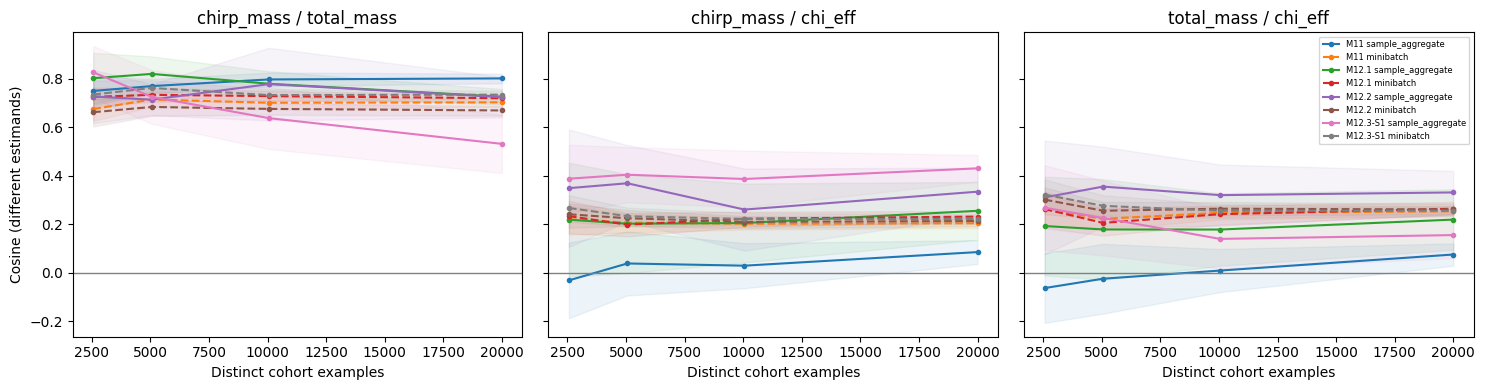

,checkpoint,region,group,pair,n_examples,n_batches,kind,metric,statistic,estimate,ci_low,ci_high,q25,q75,finite_fraction,adequate,method,stable_geometry,absolute_change
0,M11,general,shallow,chirp_mass / total_mass,20000,312,minibatch,cosine,mean,0.723082,0.699141,0.748096,0.638742,0.866832,1.0,True,paired batch percentile bootstrap; common fini...,True,0.012244
1,M12.1,general,shallow,chirp_mass / total_mass,20000,312,minibatch,cosine,mean,0.758753,0.736780,0.780623,0.672860,0.887114,1.0,True,paired batch percentile bootstrap; common fini...,True,0.011270
2,M12.2,general,shallow,chirp_mass / total_mass,20000,312,minibatch,cosine,mean,0.700587,0.672338,0.726231,0.624545,0.852837,1.0,True,paired batch percentile bootstrap; common fini...,True,0.007461
3,M12.3-S1,general,shallow,chirp_mass / total_mass,20000,312,minibatch,cosine,mean,0.781453,0.763693,0.796533,0.707895,0.891877,1.0,True,paired batch percentile bootstrap; common fini...,True,0.004666
4,M11,general,shallow,chirp_mass / total_mass,20000,312,minibatch,cosine,median,0.775220,0.748847,0.800389,0.638742,0.866832,1.0,True,paired batch percentile bootstrap; common fini...,True,0.002350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1794,M12.3-S1,general,all_shared,chirp_mass / chi_eff,20000,313,sample_aggregate,cosine,geometry_of_mean_gradient,0.430706,0.375734,0.485678,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.044017
1800,M12.3-S1,general,all_shared,total_mass / chi_eff,20000,313,sample_aggregate,cosine,geometry_of_mean_gradient,0.155096,0.059888,0.250305,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.015744
1806,M12.3-S1,general,all_shared,chirp_mass / combined_MSE,20000,313,sample_aggregate,cosine,geometry_of_mean_gradient,0.829324,0.798936,0.859712,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,True,0.001942
1812,M12.3-S1,general,all_shared,total_mass / combined_MSE,20000,313,sample_aggregate,cosine,geometry_of_mean_gradient,0.563816,0.471960,0.655671,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.051238


,checkpoint,n_examples,pair,norm_a,norm_b,norm_floor_a,norm_floor_b,undefined_cosine
18,M11,2560,chirp_mass / total_mass,0.291232,0.289812,9.236416e-07,7.292395e-07,False
19,M11,2560,chirp_mass / chi_eff,0.291232,0.336405,9.236416e-07,1.400234e-06,False
20,M11,2560,total_mass / chi_eff,0.289812,0.336405,7.292395e-07,1.400234e-06,False
21,M11,2560,chirp_mass / combined_MSE,0.291232,0.208159,9.236416e-07,7.653206e-07,False
22,M11,2560,total_mass / combined_MSE,0.289812,0.208159,7.292395e-07,7.653206e-07,False
...,...,...,...,...,...,...,...,...
955,M12.3-S1,20000,chirp_mass / chi_eff,0.324564,0.436592,1.625535e-06,1.886649e-06,False
956,M12.3-S1,20000,total_mass / chi_eff,0.169448,0.436592,1.394960e-06,1.886649e-06,False
957,M12.3-S1,20000,chirp_mass / combined_MSE,0.324564,0.242251,1.625535e-06,1.233440e-06,False
958,M12.3-S1,20000,total_mass / combined_MSE,0.169448,0.242251,1.394960e-06,1.233440e-06,False


In [10]:
large_task_pairs = [large_labels[a]+" / "+large_labels[b] for a,b in [(0,1),(0,2),(1,2)]]
fig, axes = plt.subplots(1, 3, figsize=(15,4), sharey=True)
for ax, pair in zip(axes, large_task_pairs):
    for name in large_models:
        for kind, statistic, style in [("sample_aggregate", "geometry_of_mean_gradient", "-"),
                                        ("minibatch", "mean", "--")]:
            frame = large_convergence[large_convergence.checkpoint.eq(name) & large_convergence.region.eq("general")
                & large_convergence.group.eq("all_shared") & large_convergence.pair.eq(pair)
                & large_convergence.metric.eq("cosine") & large_convergence.kind.eq(kind)
                & large_convergence.statistic.eq(statistic)].sort_values("n_examples")
            line, = ax.plot(frame.n_examples, frame.estimate, style, marker=".", label=name+" "+kind)
            ax.fill_between(frame.n_examples.to_numpy(), frame.ci_low.to_numpy(), frame.ci_high.to_numpy(),
                            alpha=.08, color=line.get_color())
    ax.axhline(0, color="gray", linewidth=1); ax.set_title(pair); ax.set_xlabel("Distinct cohort examples")
axes[0].set_ylabel("Cosine (different estimands)")
axes[-1].legend(fontsize=6)
fig.tight_layout(); plt.show()
large_primary = large_summary[large_summary.metric.isin(["cosine", "negative_cosine"])]
display(large_primary[large_primary.region.eq("general")])
# Aggregate norm/floor audit; normal intervals are displayed untruncated.
display(large_aggregate[large_aggregate.region.eq("general") & large_aggregate.group.eq("all_shared")][[
    "checkpoint","n_examples","pair","norm_a","norm_b","norm_floor_a","norm_floor_b","undefined_cosine"]])

## Regions, actual layer depth, distributions and combined-MSE alignment
Regional comparisons below are descriptive and separate from general estimates. Overlap is reported above; no test treats overlapping cohorts as independent. Task-versus-combined negative fractions refer to minibatches, while aggregate alignment is a single finite-sample geometry, not a negative fraction of observations. IQR bars describe minibatch distributions, not confidence intervals.

,checkpoint,region,group,pair,n_examples,n_batches,kind,metric,statistic,estimate,ci_low,ci_high,q25,q75,finite_fraction,adequate,method,stable_geometry,absolute_change
1824,M11,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,5000,78,minibatch,cosine,mean,0.622260,0.553715,0.679453,0.516550,0.801291,1.0,True,paired batch percentile bootstrap; common fini...,False,0.026545
1825,M12.1,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,5000,78,minibatch,cosine,mean,0.666567,0.614979,0.713938,0.555368,0.832862,1.0,True,paired batch percentile bootstrap; common fini...,False,0.002573
1826,M12.2,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,5000,78,minibatch,cosine,mean,0.674741,0.628491,0.719656,0.559756,0.840779,1.0,True,paired batch percentile bootstrap; common fini...,False,0.036138
1827,M12.3-S1,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,5000,78,minibatch,cosine,mean,0.688522,0.632151,0.740349,0.578588,0.861026,1.0,True,paired batch percentile bootstrap; common fini...,False,0.056990
1828,M11,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,5000,78,minibatch,cosine,median,0.669764,0.617895,0.756900,0.516550,0.801291,1.0,True,paired batch percentile bootstrap; common fini...,False,0.031557
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9090,M12.3-S1,total_mass_peripheral_spin_central,all_shared,chirp_mass / chi_eff,5000,79,sample_aggregate,cosine,geometry_of_mean_gradient,0.201092,0.155665,0.246520,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.049450
9096,M12.3-S1,total_mass_peripheral_spin_central,all_shared,total_mass / chi_eff,5000,79,sample_aggregate,cosine,geometry_of_mean_gradient,0.294288,0.263323,0.325253,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.035723
9102,M12.3-S1,total_mass_peripheral_spin_central,all_shared,chirp_mass / combined_MSE,5000,79,sample_aggregate,cosine,geometry_of_mean_gradient,0.872920,0.849094,0.896747,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.021893
9108,M12.3-S1,total_mass_peripheral_spin_central,all_shared,total_mass / combined_MSE,5000,79,sample_aggregate,cosine,geometry_of_mean_gradient,0.906602,0.896661,0.916542,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.012823


,checkpoint,region,group,pair,n_examples,n_batches,kind,metric,statistic,estimate,ci_low,ci_high,q25,q75,finite_fraction,adequate,method,stable_geometry,absolute_change
944,M11,general,all_shared,chirp_mass / total_mass,20000,312,minibatch,dot,mean,0.711891,0.415547,1.149901,0.182616,0.451282,1.0,True,paired batch percentile bootstrap; common fini...,False,NaN
945,M12.1,general,all_shared,chirp_mass / total_mass,20000,312,minibatch,dot,mean,2.044650,0.847521,3.502458,0.233122,0.692394,1.0,True,paired batch percentile bootstrap; common fini...,False,NaN
946,M12.2,general,all_shared,chirp_mass / total_mass,20000,312,minibatch,dot,mean,1.116282,0.447534,2.208760,0.144529,0.428534,1.0,True,paired batch percentile bootstrap; common fini...,False,NaN
947,M12.3-S1,general,all_shared,chirp_mass / total_mass,20000,312,minibatch,dot,mean,1.826868,1.202952,2.651783,0.348496,1.258710,1.0,True,paired batch percentile bootstrap; common fini...,False,NaN
948,M11,general,all_shared,chirp_mass / total_mass,20000,312,minibatch,dot,median,0.273193,0.251916,0.290639,0.182616,0.451282,1.0,True,paired batch percentile bootstrap; common fini...,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1816,M12.3-S1,general,all_shared,total_mass / combined_MSE,20000,313,sample_aggregate,norm_ratio_a_over_b,geometry_of_mean_gradient,0.699473,0.591020,0.807926,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,NaN
1819,M12.3-S1,general,all_shared,chi_eff / combined_MSE,20000,313,sample_aggregate,dot,geometry_of_mean_gradient,0.087706,0.060384,0.115028,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,NaN
1820,M12.3-S1,general,all_shared,chi_eff / combined_MSE,20000,313,sample_aggregate,norm_a,geometry_of_mean_gradient,0.436592,0.364810,0.508375,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,NaN
1821,M12.3-S1,general,all_shared,chi_eff / combined_MSE,20000,313,sample_aggregate,norm_b,geometry_of_mean_gradient,0.242251,0.214387,0.270115,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,NaN


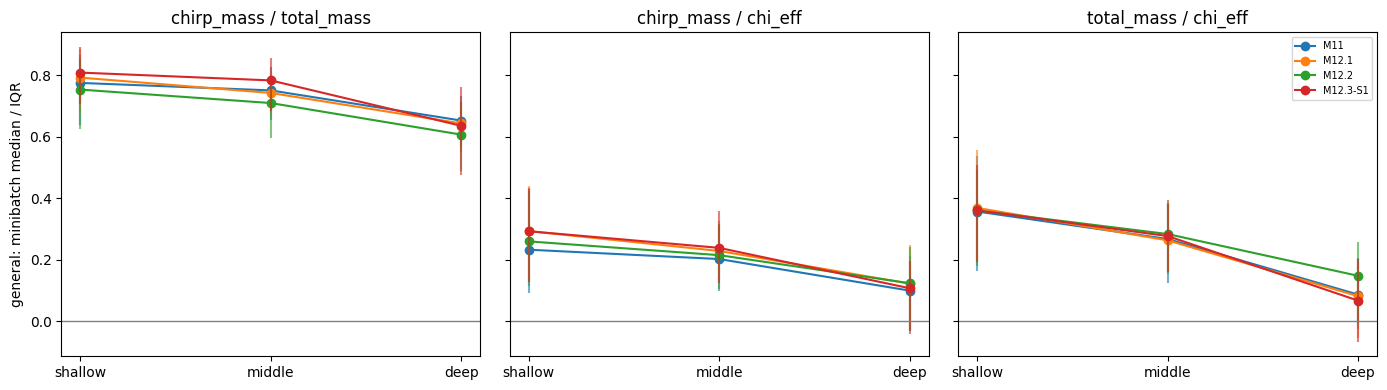

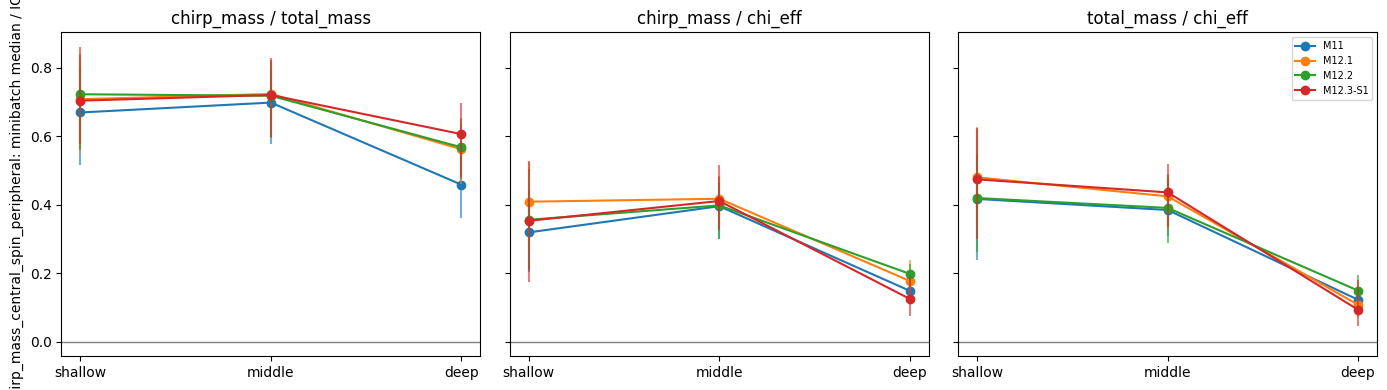

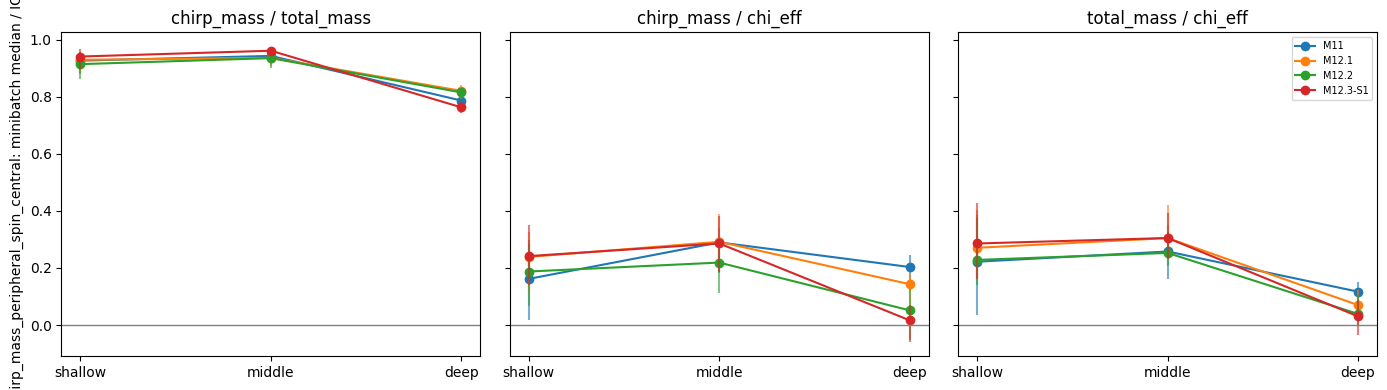

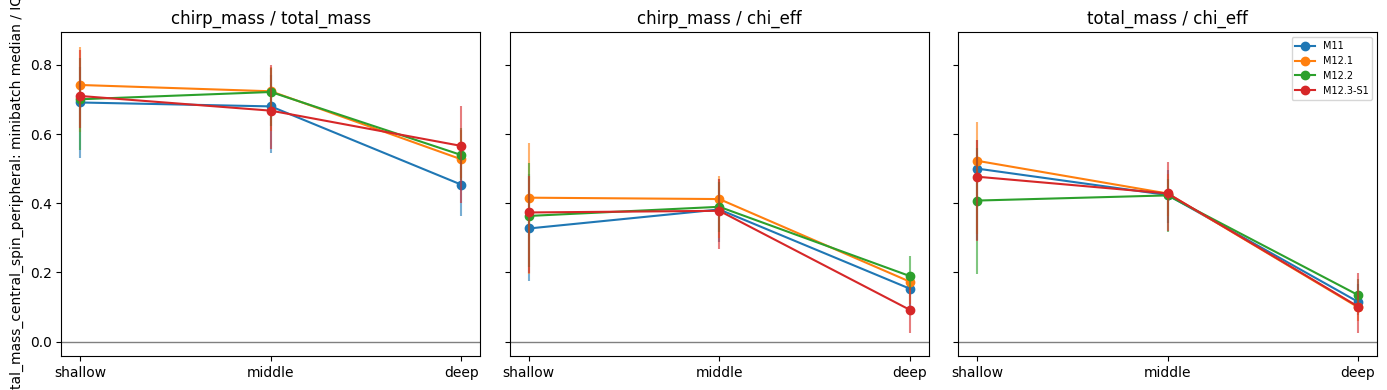

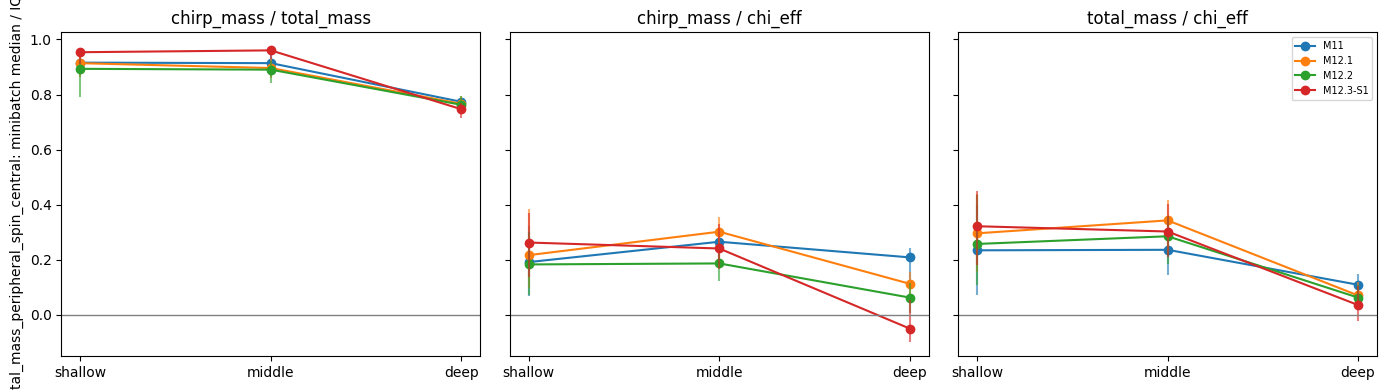

,checkpoint,region,group,pair,n_examples,n_batches,kind,metric,statistic,estimate,ci_low,ci_high,q25,q75,finite_fraction,adequate,method,stable_geometry,absolute_change
156,M11,general,shallow,chirp_mass / combined_MSE,20000,312,minibatch,cosine,mean,0.727953,0.706256,0.748837,0.625164,0.859515,1.0,True,paired batch percentile bootstrap; common fini...,True,0.000625
157,M12.1,general,shallow,chirp_mass / combined_MSE,20000,312,minibatch,cosine,mean,0.756980,0.738914,0.775876,0.675452,0.873386,1.0,True,paired batch percentile bootstrap; common fini...,True,0.002050
158,M12.2,general,shallow,chirp_mass / combined_MSE,20000,312,minibatch,cosine,mean,0.716990,0.693576,0.740130,0.619077,0.862046,1.0,True,paired batch percentile bootstrap; common fini...,True,0.007716
159,M12.3-S1,general,shallow,chirp_mass / combined_MSE,20000,312,minibatch,cosine,mean,0.775140,0.758841,0.789694,0.692207,0.885110,1.0,True,paired batch percentile bootstrap; common fini...,True,0.001634
160,M11,general,shallow,chirp_mass / combined_MSE,20000,312,minibatch,cosine,median,0.775774,0.747038,0.796252,0.625164,0.859515,1.0,True,paired batch percentile bootstrap; common fini...,False,0.009198
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1776,M12.3-S1,general,deep,total_mass / combined_MSE,20000,313,sample_aggregate,cosine,geometry_of_mean_gradient,0.267958,0.117614,0.418301,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.104101
1782,M12.3-S1,general,deep,chi_eff / combined_MSE,20000,313,sample_aggregate,cosine,geometry_of_mean_gradient,0.838998,0.785214,0.892781,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.003230
1806,M12.3-S1,general,all_shared,chirp_mass / combined_MSE,20000,313,sample_aggregate,cosine,geometry_of_mean_gradient,0.829324,0.798936,0.859712,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,True,0.001942
1812,M12.3-S1,general,all_shared,total_mass / combined_MSE,20000,313,sample_aggregate,cosine,geometry_of_mean_gradient,0.563816,0.471960,0.655671,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.051238


,checkpoint,region,group,pair,n_examples,n_batches,kind,metric,statistic,estimate,ci_low,ci_high,q25,q75,finite_fraction,adequate,method,stable_geometry,absolute_change
1980,M11,chirp_mass_central_spin_peripheral,shallow,chirp_mass / combined_MSE,5000,78,minibatch,cosine,mean,0.708241,0.663203,0.750120,0.630338,0.833697,1.0,True,paired batch percentile bootstrap; common fini...,False,0.013714
1981,M12.1,chirp_mass_central_spin_peripheral,shallow,chirp_mass / combined_MSE,5000,78,minibatch,cosine,mean,0.735626,0.694468,0.769970,0.685381,0.855768,1.0,True,paired batch percentile bootstrap; common fini...,False,0.018540
1982,M12.2,chirp_mass_central_spin_peripheral,shallow,chirp_mass / combined_MSE,5000,78,minibatch,cosine,mean,0.768932,0.736085,0.799072,0.668721,0.868741,1.0,True,paired batch percentile bootstrap; common fini...,False,0.014868
1983,M12.3-S1,chirp_mass_central_spin_peripheral,shallow,chirp_mass / combined_MSE,5000,78,minibatch,cosine,mean,0.744993,0.684510,0.788028,0.674291,0.874146,1.0,True,paired batch percentile bootstrap; common fini...,False,0.037659
1984,M11,chirp_mass_central_spin_peripheral,shallow,chirp_mass / combined_MSE,5000,78,minibatch,cosine,median,0.748761,0.705505,0.795756,0.630338,0.833697,1.0,True,paired batch percentile bootstrap; common fini...,False,0.030895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9072,M12.3-S1,total_mass_peripheral_spin_central,deep,total_mass / combined_MSE,5000,79,sample_aggregate,cosine,geometry_of_mean_gradient,0.850718,0.834566,0.866870,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.016516
9078,M12.3-S1,total_mass_peripheral_spin_central,deep,chi_eff / combined_MSE,5000,79,sample_aggregate,cosine,geometry_of_mean_gradient,0.434877,0.377311,0.492443,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.022923
9102,M12.3-S1,total_mass_peripheral_spin_central,all_shared,chirp_mass / combined_MSE,5000,79,sample_aggregate,cosine,geometry_of_mean_gradient,0.872920,0.849094,0.896747,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.021893
9108,M12.3-S1,total_mass_peripheral_spin_central,all_shared,total_mass / combined_MSE,5000,79,sample_aggregate,cosine,geometry_of_mean_gradient,0.906602,0.896661,0.916542,NaN,NaN,1.0,True,weighted delete-group normal approximation wit...,False,0.012823


,reference,checkpoint,region,group,pair,n_examples,kind,metric,statistic,estimate,ci_low,ci_high,method
0,M11,M12.1,general,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,0.037079,-0.023990,0.085651,paired batch bootstrap; no between-region or b...
1,M11,M12.2,general,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,-0.011876,-0.064462,0.037246,paired batch bootstrap; no between-region or b...
2,M11,M12.3-S1,general,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,0.069567,0.024137,0.117152,paired batch bootstrap; no between-region or b...
3,M12.1,M12.2,general,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,-0.048955,-0.114886,0.011276,paired batch bootstrap; no between-region or b...
4,M12.1,M12.3-S1,general,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,0.032489,-0.021995,0.092906,paired batch bootstrap; no between-region or b...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10914,M12.2,M12.3-S1,general,all_shared,chirp_mass / chi_eff,20000,sample_aggregate,cosine,geometry_of_mean_gradient,0.096421,0.017207,0.175635,paired delete-group delta; aggregate FPC; no c...
10920,M12.2,M12.3-S1,general,all_shared,total_mass / chi_eff,20000,sample_aggregate,cosine,geometry_of_mean_gradient,-0.176159,-0.272915,-0.079403,paired delete-group delta; aggregate FPC; no c...
10926,M12.2,M12.3-S1,general,all_shared,chirp_mass / combined_MSE,20000,sample_aggregate,cosine,geometry_of_mean_gradient,0.056015,-0.012005,0.124034,paired delete-group delta; aggregate FPC; no c...
10932,M12.2,M12.3-S1,general,all_shared,total_mass / combined_MSE,20000,sample_aggregate,cosine,geometry_of_mean_gradient,-0.246087,-0.345621,-0.146554,paired delete-group delta; aggregate FPC; no c...


,reference,checkpoint,region,group,pair,n_examples,kind,metric,statistic,estimate,ci_low,ci_high,method
10944,M11,M12.1,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,0.073425,-0.008901,0.179020,paired batch bootstrap; no between-region or b...
10945,M11,M12.2,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,0.042888,-0.004119,0.095416,paired batch bootstrap; no between-region or b...
10946,M11,M12.3-S1,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,0.035817,-0.006475,0.082119,paired batch bootstrap; no between-region or b...
10947,M12.1,M12.2,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,-0.030537,-0.105380,0.033821,paired batch bootstrap; no between-region or b...
10948,M12.1,M12.3-S1,chirp_mass_central_spin_peripheral,shallow,chirp_mass / total_mass,2560,minibatch,cosine,mean,-0.037608,-0.144506,0.044278,paired batch bootstrap; no between-region or b...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32802,M12.2,M12.3-S1,total_mass_peripheral_spin_central,all_shared,chirp_mass / chi_eff,5000,sample_aggregate,cosine,geometry_of_mean_gradient,-0.003485,-0.051589,0.044618,paired delete-group delta; aggregate FPC; no c...
32808,M12.2,M12.3-S1,total_mass_peripheral_spin_central,all_shared,total_mass / chi_eff,5000,sample_aggregate,cosine,geometry_of_mean_gradient,0.048261,0.014962,0.081559,paired delete-group delta; aggregate FPC; no c...
32814,M12.2,M12.3-S1,total_mass_peripheral_spin_central,all_shared,chirp_mass / combined_MSE,5000,sample_aggregate,cosine,geometry_of_mean_gradient,-0.000714,-0.025670,0.024243,paired delete-group delta; aggregate FPC; no c...
32820,M12.2,M12.3-S1,total_mass_peripheral_spin_central,all_shared,total_mass / combined_MSE,5000,sample_aggregate,cosine,geometry_of_mean_gradient,0.014927,0.001596,0.028257,paired delete-group delta; aggregate FPC; no c...


,checkpoint,region,group,pair,kind,statistic,metric,n_examples,estimate,ci_low,ci_high,assessment
0,M11,general,shallow,chirp_mass / total_mass,minibatch,mean,cosine,20000,0.723082,0.699141,0.748096,meets predefined descriptive stability
1,M12.1,general,shallow,chirp_mass / total_mass,minibatch,mean,cosine,20000,0.758753,0.736780,0.780623,meets predefined descriptive stability
2,M12.2,general,shallow,chirp_mass / total_mass,minibatch,mean,cosine,20000,0.700587,0.672338,0.726231,meets predefined descriptive stability
3,M12.3-S1,general,shallow,chirp_mass / total_mass,minibatch,mean,cosine,20000,0.781453,0.763693,0.796533,meets predefined descriptive stability
4,M11,general,shallow,chirp_mass / total_mass,minibatch,median,cosine,20000,0.775220,0.748847,0.800389,meets predefined descriptive stability
...,...,...,...,...,...,...,...,...,...,...,...,...
9090,M12.3-S1,total_mass_peripheral_spin_central,all_shared,chirp_mass / chi_eff,sample_aggregate,geometry_of_mean_gradient,cosine,5000,0.201092,0.155665,0.246520,adequate interval; convergence not established
9096,M12.3-S1,total_mass_peripheral_spin_central,all_shared,total_mass / chi_eff,sample_aggregate,geometry_of_mean_gradient,cosine,5000,0.294288,0.263323,0.325253,adequate interval; convergence not established
9102,M12.3-S1,total_mass_peripheral_spin_central,all_shared,chirp_mass / combined_MSE,sample_aggregate,geometry_of_mean_gradient,cosine,5000,0.872920,0.849094,0.896747,adequate interval; convergence not established
9108,M12.3-S1,total_mass_peripheral_spin_central,all_shared,total_mass / combined_MSE,sample_aggregate,geometry_of_mean_gradient,cosine,5000,0.906602,0.896661,0.916542,adequate interval; convergence not established


In [11]:
display(large_primary[~large_primary.region.eq("general")])
large_norms = large_summary[large_summary.metric.isin(["norm_a", "norm_b", "dot", "norm_ratio_a_over_b"])]
display(large_norms[large_norms.region.eq("general") & large_norms.group.eq("all_shared")])
for cohort in large_design["cohorts"]:
    fig, axes = plt.subplots(1, 3, figsize=(14,4), sharey=True)
    for ax, pair in zip(axes, large_task_pairs):
        for name in large_models:
            frame = large_summary[large_summary.checkpoint.eq(name) & large_summary.region.eq(cohort)
                & large_summary.pair.eq(pair) & large_summary.metric.eq("cosine")
                & large_summary.kind.eq("minibatch") & large_summary.statistic.eq("median")].set_index("group").reindex(["shallow","middle","deep"])
            line, = ax.plot(range(3), frame.estimate, marker="o", label=name)
            ax.vlines(range(3), frame.q25, frame.q75, color=line.get_color(), alpha=.6)
        ax.axhline(0, color="gray", linewidth=1); ax.set_xticks(range(3)); ax.set_xticklabels(["shallow","middle","deep"])
        ax.set_title(pair)
    axes[0].set_ylabel(cohort+": minibatch median / IQR")
    axes[-1].legend(fontsize=7); fig.tight_layout(); plt.show()
large_alignment = large_primary[large_primary.pair.str.endswith(" / combined_MSE")]
display(large_alignment[large_alignment.region.eq("general")])
display(large_alignment[~large_alignment.region.eq("general")])
# Paired differences retain identical cohort/batch identities and matching delete groups.
if len(large_paired):
    display(large_paired[large_paired.region.eq("general") & large_paired.metric.eq("cosine")])
    display(large_paired[~large_paired.region.eq("general") & large_paired.metric.eq("cosine")])
large_evidence = large_primary.copy()
large_evidence["assessment"] = np.where(large_evidence.stable_geometry,
    "meets predefined descriptive stability", np.where(large_evidence.adequate,
    "adequate interval; convergence not established", "indeterminate"))
display(large_evidence[["checkpoint","region","group","pair","kind","statistic","metric","n_examples",
                        "estimate","ci_low","ci_high","assessment"]])

## Interpretation record — complete only after a new run

- **Integrity/design:** [input hashes, selected cohorts, actual distinct union, sample fractions, overlap, partial batches, runtime/peak GPU memory, frozen-state checks and coverage]. No non-train labels are used. Checkpoint/file hashes identify actual inputs, not independent historical authenticity.
- **Population scope:** [general sample versus regional cohorts; distinguish sample aggregate from an exact eligible-population census]. Small mean norms may reflect cancellation; undefined cosine is not zero conflict.
- **Geometry:** [mass–mass and both mass–spin pairs, minibatch distributions versus aggregate cosines, norms/dots, layer depth and task alignment to combined MSE]. Gradient orientations at trained endpoints cannot establish harmful interference throughout training or justify a new architecture by themselves.
- **Evidence:** [which predeclared adequacy/stability conditions are met, which remain indeterminate, and how paired model intervals differ]. Single checkpoints give no training-seed variability. Delete-group normal and batch bootstrap intervals are finite-sample approximations; overlap prohibits independent region pooling. Numerous dependent comparisons are exploratory, not family-wise claims. Nested sample prefixes are correlated, and stabilization does not prove convergence to population truth.
- **Decision:** [scientific interpretation and whether a separate controlled intervention merits approval]. Do not launch follow-on training. Future predictor selection still uses validation and the provisional≤2% per-label RMSE guardrail, slopes, tails, low SNR and chi_eff diagnostics; changed predictors require newly fitted calibration quantiles only after selection.

## VM commands and exports

Compatibility pilot (same v1 interface/schema and4 batches of32):

```bash
python scripts/m12/run_m12_4_1_gradient_diagnostics.py --models M11 --device cpu --pilot --max-batches 4 --batch-size 32 --seed 123 --output-dir "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_4_1/compat_pilot_seed123_v2"
```

40,000-example general-population study, four checkpoints:

```bash
python scripts/m12/run_m12_4_1_gradient_diagnostics.py --large-sample --models M11 M12.1 M12.2 M12.3-S1 --device cuda --examples 40000 --batch-size 64 --seed 123 --output-dir "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_4_1/large_general40k_seed123_v1"
```

Optional **separate** regional design with the same ceiling: add `--regions chirp_mass_central_spin_peripheral total_mass_peripheral_spin_central --region-examples 5000` and change output tag. This allocates30,000 general+5,000+5,000 regional exposures, at most40,000 distinct rows,627 batches/model because partial cohort batches are retained (7,524 task backward calls across four models). It does not allocate40,000 per region. These new cohorts are not retroactively appended to an existing run. Explicit `--examples 80000` or up to400,000 is required for larger studies. The budget is fixed in advance; do not stop/extend based on favorable interim confidence intervals.

The script keeps one checkpoint, one cohort's delete-group sums and one batch graph in memory. Aggregate workspace cap256MiB and scalar-cache cap128MiB are checked; batch size≤64, train population≤400,000, and ≤4 selected models bound other arrays. CPU process RSS also includes imports, model copies, train-label metadata and temporary scalar-bootstrap arrays; the caps are not a promise about total RSS. GPU peak allocation is recorded, not guaranteed in advance. No mixed precision or new dependencies. PyTorch1.9.1/P100 execution still requires a manual pilot.

Schema v1 exports remain unchanged. Schema v2 adds compact `batch_index.csv` (one row per batch), `batch_manifest.csv` (one row per selected cohort observation), and deduplicated `sample_annotations.csv`. `gradients_per_batch.csv` stores scalar geometry for three task pairs plus three task/combined alignments across four groups. `aggregate_gradients.csv` stores sample-aggregate geometry and approximate intervals at cumulative counts. `aggregate_delete_groups.csv` contains only scalar leave-group metrics for auditing paired intervals, never full vectors. `convergence.csv` and final `gradients_summary.csv` contain long-form estimates, intervals, quantiles and predeclared adequacy/stability flags; `paired_comparisons.csv` contains all available model-pair differences. `coverage.csv`, `timings.csv`, `run_metadata.json` and `progress.json` record integrity and provenance.

`progress.json` is updated atomically after scalar CSVs are flushed at cumulative checkpoints and state integrity is verified. **No resume**: interrupted runs must restart in a new directory; the notebook rejects runs without completed metadata. Cumulative output checkpoints are not model checkpoints. No previous output directory is overwritten. Copy the new directory's CSV/JSON files to the local external data root with user-operated non-deleting `rsync`; never sync strain or weights for notebook analysis. Keep the initial `full_seed123_v1` and `pilot_cuda_seed123_v1` directories unchanged.

Focused checks: `PYTHONDONTWRITEBYTECODE=1 OMP_NUM_THREADS=2 MKL_NUM_THREADS=2 python -m unittest discover -s tests -p 'test_m12_4_1_gradient_diagnostics.py'`. Synthetic arrays only; no research inference or notebook execution.